# Images are arrays: MNIST with NumPy

MNIST is a classic dataset of handwritten digits: 60,000 training images and 10,000 test images, each labelled with the digit it shows. Every image is a 28×28 grid of numbers, so a set of images is a NumPy array, and everything you do to images (scaling, adding noise, shifting, cropping) is array manipulation.

**How to work**

- Solve each exercise in the empty cell below it, adding cells if you need them. Use NumPy, and matplotlib only to plot.
- Keep the names the exercises ask for: the tests look for them. Check your work with the tests, as the [README](README.md#3-run-the-tests-they-fail) explains.
- Do a first pass **without an AI assistant**: the point is to learn how arrays behave, and you can only judge an assistant's answer once you know that. Then ask an assistant for another way to solve two of the exercises, time both versions, and write down which one is better and why.
- A solution that compares alternative approaches is in [mnist_numpy_solution.ipynb](mnist_numpy_solution.ipynb). Open it after trying.

## Loading MNIST

The images come from the [MNIST database](https://en.wikipedia.org/wiki/MNIST_database). Its authors **scaled** each black-and-white digit to fit a 20×20 box, keeping its proportions, which smoothed the edges into grey levels. Then they placed it in a 28×28 frame with its centre of mass at the centre. Each pixel is a grey level: a number from 0 to 255.

The dataset is downloaded as one `.npz` file, a zip of several NumPy arrays, from the address Keras uses. Its SHA-256 checksum is compared with the published one, so a corrupted download is detected. The file is kept in a `data/` folder that git ignores, so it is downloaded only once. `type ImagesAndLabels = ...` gives a name to a type, so that the signature of `load_mnist` stays readable.

In [1]:
import hashlib
import urllib.request
from pathlib import Path

import numpy as np

MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
MNIST_SHA256 = "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1"

type ImagesAndLabels = tuple[np.ndarray, np.ndarray]


def load_mnist(cache_dir: Path = Path("data")) -> tuple[ImagesAndLabels, ImagesAndLabels]:
    """Download MNIST into `cache_dir` once, check it, and return its (train, test) splits."""
    cache_dir.mkdir(exist_ok=True)
    path = cache_dir / "mnist.npz"
    if not path.exists():
        urllib.request.urlretrieve(MNIST_URL, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != MNIST_SHA256:
        path.unlink()
        raise ValueError("The download is corrupted and has been deleted: run the cell again")
    with np.load(path) as mnist:
        return (mnist["x_train"], mnist["y_train"]), (mnist["x_test"], mnist["y_test"])


(X_train, y_train), (X_test, y_test) = load_mnist()

`X_train` holds the training images and `y_train` their **labels**. The usual convention in machine learning is a capital `X` for the inputs, because they usually form a matrix with one row per sample and one column per feature, and a lowercase `y` for the targets, a vector with one value per sample. Here `X_train` has three dimensions, one 28×28 image per sample; exercise 2 turns it into that matrix.

In [2]:
type(X_train), X_train.dtype, X_train.shape

(numpy.ndarray, dtype('uint8'), (60000, 28, 28))

A NumPy array of 60,000 images of 28×28 pixels: three dimensions. Its type is `uint8`, an unsigned 8-bit integer, so every pixel is an integer from 0 to 255, where 0 is the background and 255 the darkest ink. At one byte per pixel, the whole training set takes about 47 MB.

In [3]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

The labels are the digits 0 to 9, one per image. The first image, as numbers:

In [4]:
def print_pixel_values(image: np.ndarray) -> None:
    for row in image:
        print("".join(f"{pixel:4}" for pixel in row))


print_pixel_values(X_train[0])

   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0
   0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0
   0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0
   0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   0   0   0   0   0

and in a more elegant way, using the **matplotlib** library:

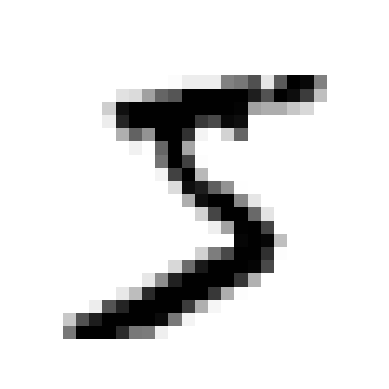

In [5]:
import matplotlib.pyplot as plt


def plot_image(image: np.ndarray) -> None:
    plt.imshow(image, cmap="binary")
    plt.axis("off")
    plt.show()


plot_image(X_train[0])

The colour map decides how numbers become colours. With `cmap="binary"`, 0 is drawn white and 255 black, like ink on paper; with `cmap="gray"`, the same array shows a white digit on a black background. The array doesn't change, only its picture.

In [6]:
y_train[0]

np.uint8(5)

The first 100 training images:

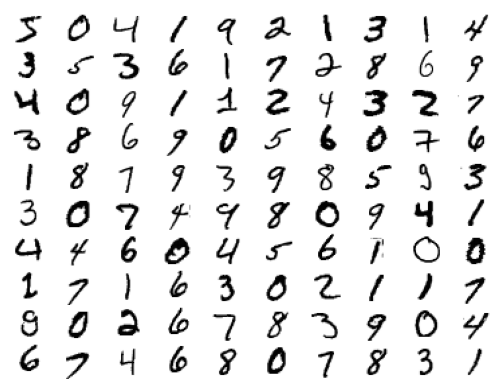

In [7]:
def plot_first_100(images: np.ndarray) -> None:
    for index, image in enumerate(images[:100]):
        plt.subplot(10, 10, index + 1)
        plt.imshow(image, cmap="binary")
        plt.axis("off")
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.show()


plot_first_100(X_train)

## Exercises

### Shapes and indexing

**1.** Create `matrix_first_100_labels`, a 10×10 array with the first 100 labels, and display it. It should match the grid of images above.

In [8]:
# Selecciono los primeros 100 elementos del array y_train
matrix_first_100_labels = y_train[:100].reshape(10,10)

# Los muestro
print(matrix_first_100_labels)


[[5 0 4 1 9 2 1 3 1 4]
 [3 5 3 6 1 7 2 8 6 9]
 [4 0 9 1 1 2 4 3 2 7]
 [3 8 6 9 0 5 6 0 7 6]
 [1 8 7 9 3 9 8 5 9 3]
 [3 0 7 4 9 8 0 9 4 1]
 [4 4 6 0 4 5 6 1 0 0]
 [1 7 1 6 3 0 2 1 1 7]
 [9 0 2 6 7 8 3 9 0 4]
 [6 7 4 6 8 0 7 8 3 1]]


**2.** Many models expect each example as one flat row of numbers: each 28×28 image becomes a vector of 784 pixels. Create `X_train_flat` and `X_test_flat`, with shapes 60,000×784 and 10,000×784.

In [9]:
X_train_flat = X_train.reshape(60000,784)
X_test_flat  = X_test.reshape(10000,784)

**3.** Change `plot_image` so that it accepts both a 28×28 image and a flat row of 784 pixels. Check it with `X_train_flat[0]`.

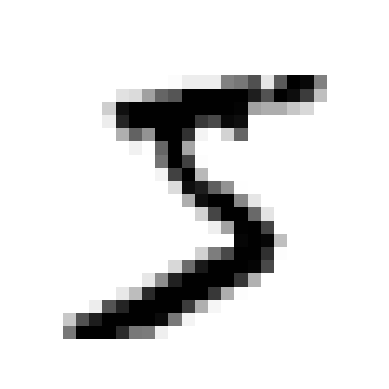

In [10]:
def plot_image(image: np.ndarray) -> None:
    if image.ndim==1:                        #Comprueba si es unidimensional                  
        image=image.reshape(28,28)           #Lo convierte a (28,28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")
    plt.show()

plot_image(X_train_flat[0])

**4.** Check, with one expression and no loop, that the bottom-right pixel is 0 in every training image.

In [11]:
es_cero=np.all(X_train[:,-1,-1] == 0)
if es_cero:
	print("Éxito => son cero")
else:
	print ("Fallo => No todos los pixeles son cero")

Éxito => son cero


**5.** Does any digit touch the edge of its frame? Store in `n_touching_border` the number of training images with ink (a non-zero pixel) in their first or last row or column.

In [12]:
n_touching_border=0

for imagen in X_train:
    if (np.any(imagen[ 0, :] !=0 ) or
    	np.any(imagen[-1, :] !=0 ) or
        np.any(imagen[ :, 0] !=0 ) or
   		np.any(imagen[ :,-1] !=0)):
	    n_touching_border+=1

print("Hay ",n_touching_border," imágenes que tocan el borde")

Hay  813  imágenes que tocan el borde


### Data types

**6.** Compute `X_train[0] + X_train[0]` and look at its maximum. Then compute the same sum correctly, and store in `n_overflowed_pixels` the number of pixels where the two results differ. Why do they differ?

In [13]:
print("Ejercicio 6\n")
print("Suma directa\n")
suma=X_train[0]+X_train[0]
print(suma.max())
print("suma correcta, convertimos a int32 con astype()")
suma_correcta=X_train[0].astype(np.int32)+X_train[0].astype(np.int32)
print(suma_correcta.max())
print("Comprobamos si los valores son mayores o iguales a 128, si son mayores al sumar desbordará")
n_overflowed_pixels = np.count_nonzero(X_train[0] >= 128)

Ejercicio 6

Suma directa

254
suma correcta, convertimos a int32 con astype()
510
Comprobamos si los valores son mayores o iguales a 128, si son mayores al sumar desbordará


### One-hot encoding

**7.** Some models expect each label as a ***one-hot* vector**: ten numbers, all 0 except a 1 at the position of the digit. Label 5 becomes `[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]`. Create `y_train_onehot` and `y_test_onehot`.

In [14]:
print("Empleamos la función np.eye\\(\\) que crea una matriz identidad de 10x10\n")
y_train_onehot=np.eye(10,dtype=int)[y_train]
y_test_onehot=np.eye(10,dtype=int)[y_test]
print("y_train_onehot=> ",y_train_onehot,end=("\n"))
print("y_test_onehot=> ",y_test_onehot,end=("\n"))

Empleamos la función np.eye\(\) que crea una matriz identidad de 10x10

y_train_onehot=>  [[0 0 0 ... 0 0 0]
 [1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 1 0]]
y_test_onehot=>  [[0 0 0 ... 1 0 0]
 [0 0 1 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


### Normalisation and standardisation

**8.** Display the minimum, maximum, mean and standard deviation of the pixels of the training images.

In [15]:
print("Ejercicio 8")

# np tiene funciónes para mostrar esos valores
print("Datos de los pixels de las imágenes de entrenamiento\n")
print("Máximo => ",np.max(X_train),
    " Mínino => ",np.min(X_train),
    " Media => ",np.mean(X_train),
    " Desviación estándar => ",np.std(X_train),sep=":::",end=(" :::"))

Ejercicio 8
Datos de los pixels de las imágenes de entrenamiento

Máximo => :::255::: Mínino => :::0::: Media => :::33.318421449829934::: Desviación estándar => :::78.56748998339798 :::

**9.** Scale the training images to the range [0, 1] as `X_train_norm`, of type `float32`, and plot its first image.

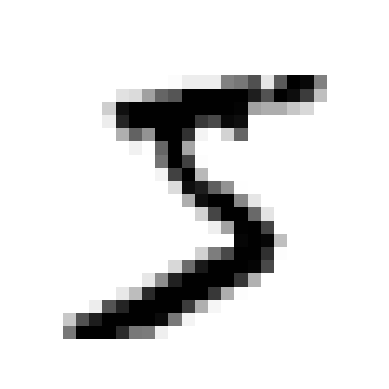

In [16]:
#Convertimos con astype
X_train_norm=(X_train/255.00).astype(np.float32)
# Reutilizamos la función plot_image y mostramos
plot_image(X_train_norm[0])

**10.** Store in `pixel_norm_mean` and `pixel_norm_std` the mean and the standard deviation of the pixels of `X_train_norm`. You will meet these two numbers again.

In [17]:
print("Ejercicio 10")

#Volvemos a calcular mean y std, ahora de X_train_norm (Con los valores normalizados)

pixel_norm_mean= np.mean(X_train_norm)
pixel_norm_std= np.std(X_train_norm)

print("pixel_norm_mean => ",pixel_norm_mean," pixel_norm_std =>",pixel_norm_std)

Ejercicio 10
pixel_norm_mean =>  0.13066047  pixel_norm_std => 0.3081078





**11.** *Standardise* the images: subtract the mean and divide by the standard deviation, so that the pixels have mean 0 and standard deviation 1.

$$X_{std} = \frac{X - \mu}{\sigma}$$

Create `X_train_standardized` and `X_test_standardized`. Compute μ and σ on the **training** images only, and use those same two numbers for the test images.

In [18]:
print("Ejercicio 11")

# Numpy nos permite vectorizar operaciones en sus elementos, no 
# necesitamos un bucle para estandarizar uno a uno los elementos

# Como con X_train_norm, hacemos X_test_norm
X_test_norm=(X_test/255.00).astype(np.float32)

X_train_standardized=(X_train_norm - pixel_norm_mean) / pixel_norm_std
X_test_standardized=(X_test_norm - pixel_norm_mean) / pixel_norm_std
print("Media estandarizada de X_train => ",X_train_standardized.mean(),"\n")
print("Desviación  estandar de X_test => ",X_train_standardized.std(),"\n")
print("Comparación\n")
print("Antes  X_train_norm[0,10,10] \n",X_train_norm[0,10,10],"\n")
print("Despues X_train_standardized[0,10,10]\n",X_train_standardized[0,10,10],"\n")

Ejercicio 11
Media estandarizada de X_train =>  2.2421078e-08 

Desviación  estandar de X_test =>  1.0 

Comparación

Antes  X_train_norm[0,10,10] 
 0.003921569 

Despues X_train_standardized[0,10,10]
 -0.411346 



**12.** Standardise `X_train_norm`, the images scaled to [0, 1], the same way, as `X_train_norm_standardized`. Check with `np.allclose` that it equals `X_train_standardized`. Why must they be equal?

In [19]:
X_train_norm_standardized=(X_train_norm - X_train_norm.mean())/X_train_norm.std()
if np.allclose(X_train_norm_standardized,X_train_standardized):
    print("\nX_train_norm_standardized y X_train_standardized son aproximadamente iguales")
print("\nLos valores son practicamente iguales debido a todos los valores se dividen entre\n"
    "255 por lo tanto ese factor se cancela al estandarizar")


X_train_norm_standardized y X_train_standardized son aproximadamente iguales

Los valores son practicamente iguales debido a todos los valores se dividen entre
255 por lo tanto ese factor se cancela al estandarizar


### Loops and vectorisation

**13.** Write `normalize_with_loops(images)`, which scales the images to [0, 1] with Python loops over every pixel, as you would without NumPy. Time it against `images / 255` on the first 1,000 training images with `time.perf_counter`, and store in `speedup` how many times faster the vectorised version is. The `compare-python-c-efficiency` repository explains where the difference comes from.

In [20]:
#Creo la función normalize_with_loops(images) que recorre las imágenes y sus píxeles con bucles for
def normalize_with_loops(images):
    resultado = images.astype(float)

    for i in range(len(resultado)):
        for j in range(len(resultado[i])):
            for k in range(len(resultado[i][j])):
                resultado[i][j][k] /= 255

    return resultado
 

#Activamos time.perf_counter() para medir el tiempo de ejecución
import time
inicio_bucle_normal=time.perf_counter()

#Llamo a la función
normalize_with_loops(X_train[:1000])

#termino de medir el tiempo
fin_bucle_normal=time.perf_counter() - inicio_bucle_normal

#Lo mostramos
print("Tiempo de ejecución con bucles normales => ",fin_bucle_normal)

#Hacemos lo mismo con la versión vectorizada de NumPy
inicio_vectorizado=time.perf_counter()
(X_train[:1000]/255)
fin_vectorizado=time.perf_counter() - inicio_vectorizado

#Lo mostramos
print("Tiempo de ejecución con vectorizado => ",fin_vectorizado)    

#Calculamos cuantas veces es más rápida la versión vectorizada
speedup = fin_bucle_normal / fin_vectorizado
print("La versión vectorizada es ",speedup," veces más rápida que la versión con bucles normales")

Tiempo de ejecución con bucles normales =>  0.2707577900000615
Tiempo de ejecución con vectorizado =>  0.0005914270000175748
La versión vectorizada es  457.8042429446334  veces más rápida que la versión con bucles normales


### Data augmentation

*Data augmentation* creates new training examples by transforming the ones you have: a digit shifted a few pixels, or with some noise, is still the same digit. A model trained on the augmented set sees more variety and generalises better. Deep-learning libraries do it for you; here you do it by hand.

**14.** Write `add_gaussian_noise(images, std)`, which adds random noise from a normal distribution with mean 0 and standard deviation `std` to every pixel, and returns images of the same type and range as the input (`uint8`, 0 to 255). Create `X_train_noisy` with `std=50`, and plot the first 100 images.

> **Gaussian noise is random noise that follows a normal distribution.** It can be applied to images to simulate non-ideal image capture conditions. This can help make machine learning models more robust.
>
> `rng = np.random.default_rng(seed=0)` gives you a random generator, and `rng.normal` draws numbers from a normal distribution. The seed makes the noise the same every time you run the notebook.

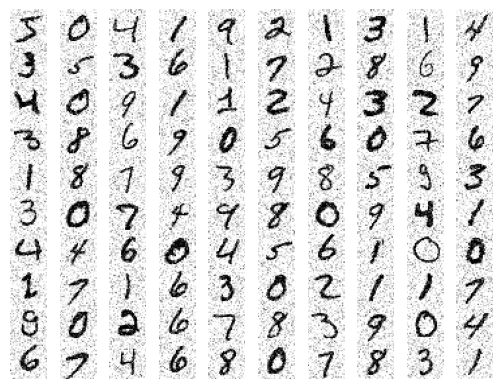

In [21]:
def add_gaussian_noise(images: np.ndarray, std: float) -> np.ndarray:
    rng = np.random.default_rng(seed=0)

    noise = rng.normal(0, std, images.shape)

    noisy_images = images.astype(np.float32) + noise
    noisy_images = np.clip(noisy_images, 0, 255)

    return noisy_images.astype(np.uint8)

X_train_noisy = add_gaussian_noise(X_train, std=50)
plot_first_100(X_train_noisy)

**15.** Write `binarize_image(image, threshold)`, which returns 1 where a pixel is greater than `threshold` and 0 elsewhere, as `uint8`. It must work for one image and for a whole array of images. Create `X_train_binarized` with threshold 128 and plot the first 100 images.

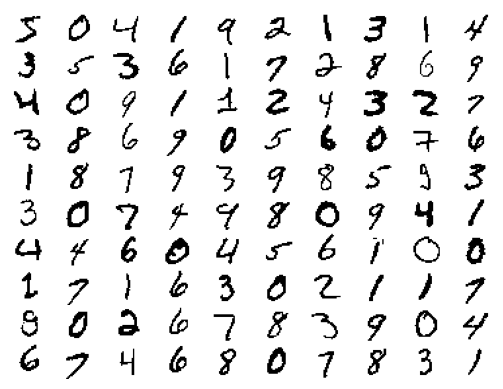

In [28]:
def binarize_image(image, threshold):
    Xtb=np.where(image>threshold,1,0).astype(np.uint8)
    return Xtb

X_train_binarized=binarize_image(X_train,128)
plot_first_100(X_train_binarized)  

**16.** Plot the first 100 training images binarised with thresholds 80 and 180, one cell each. What changes?

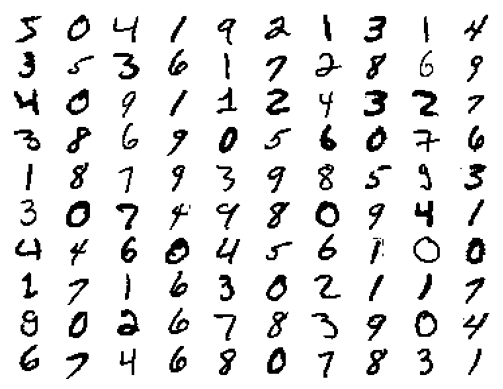

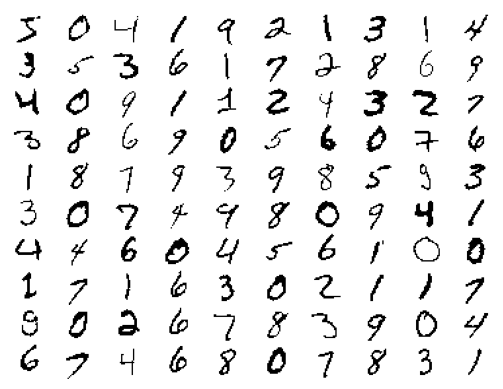

Con el umbral más bajo, se descartan menos píxeles, por eso se ven trazos más gruesos


In [30]:
X_train_bin_80 = binarize_image(X_train, threshold=80)
plot_first_100(X_train_bin_80)
X_train_bin_180 = binarize_image(X_train, threshold=180)
plot_first_100(X_train_bin_180)

print("Con el umbral más bajo, se descartan menos píxeles, por eso se ven trazos más gruesos")

**17.** Create `X_train_noisy_binarized` by binarising the noisy images with threshold 128, and plot the first 100. Try other thresholds: which one removes most of the noise without breaking the digits?

X_train_noisy_binarized con umbral 128


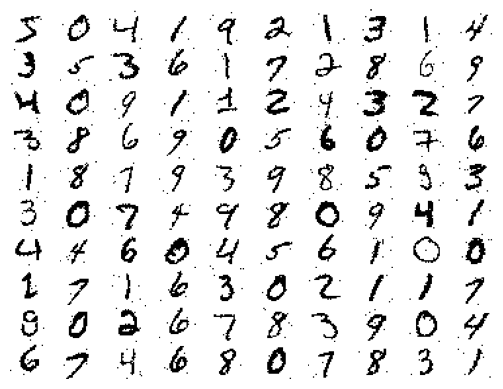

X_train_noisy_binarized con umbral 8


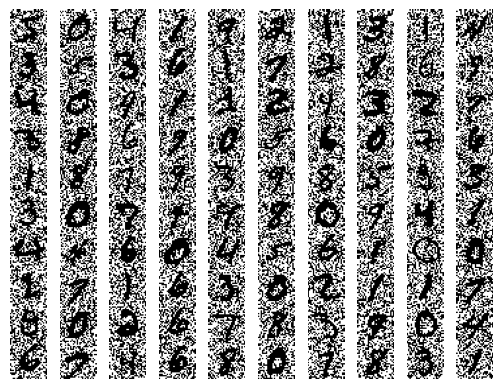

X_train_noisy_binarized con umbral 80


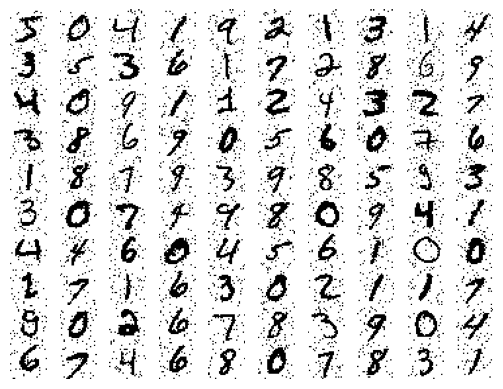

X_train_noisy_binarized con umbral 180


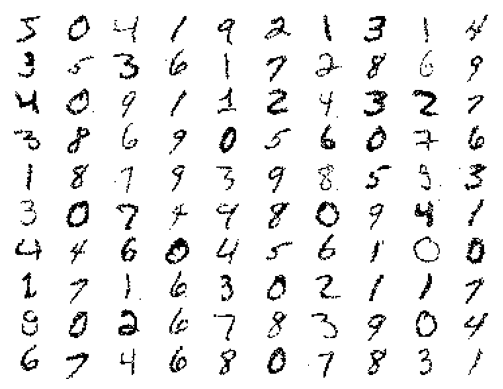

X_train_noisy_binarized con umbral 240


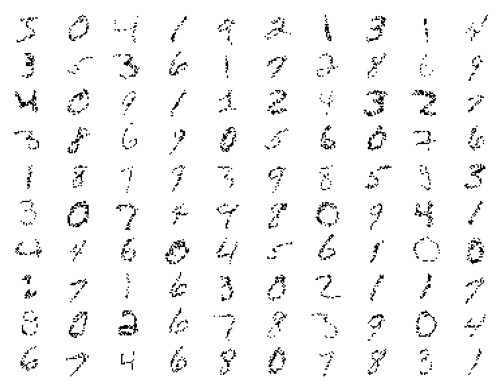

Si el umbral es muy bajo, se observa ruido, si es muy alto se pierden detalles


In [34]:
print("X_train_noisy_binarized con umbral 128")
X_train_noisy_binarized=binarize_image(X_train_noisy,128)
plot_first_100(X_train_noisy_binarized)

print("X_train_noisy_binarized con umbral 8")
X_train_noisy_binarized=binarize_image(X_train_noisy,8)
plot_first_100(X_train_noisy_binarized)

print("X_train_noisy_binarized con umbral 80")
X_train_noisy_binarized=binarize_image(X_train_noisy,80)
plot_first_100(X_train_noisy_binarized)     

print("X_train_noisy_binarized con umbral 180")
X_train_noisy_binarized=binarize_image(X_train_noisy,180)
plot_first_100(X_train_noisy_binarized)   

print("X_train_noisy_binarized con umbral 240")
X_train_noisy_binarized=binarize_image(X_train_noisy,240)
plot_first_100(X_train_noisy_binarized)  

print("Si el umbral es muy bajo, se observa ruido, si es muy alto se pierden detalles")


**18.** Write `shift_image(image, dx, dy)`, which moves an image `dx` pixels to the right (to the left if negative) and `dy` pixels down (up if negative), filling the space left behind with 0. Plot the first image shifted 10 pixels in each of the four directions, one cell each.

No hay desplazamiento


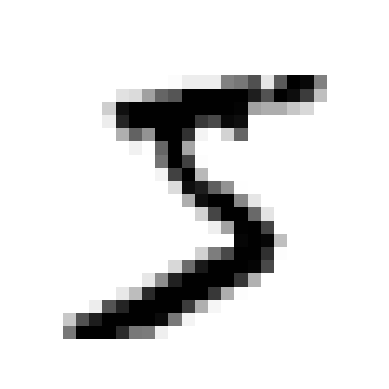

Derecha 10 píxeles


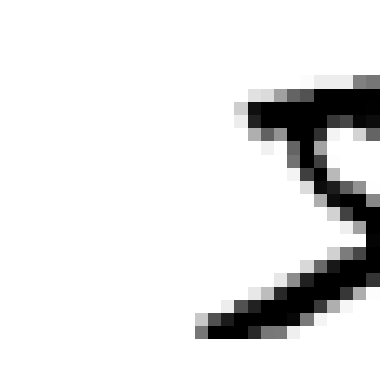

Izquierda 10 píxeles


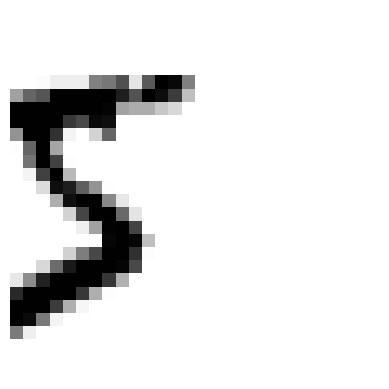

Abajo 10 píxeles


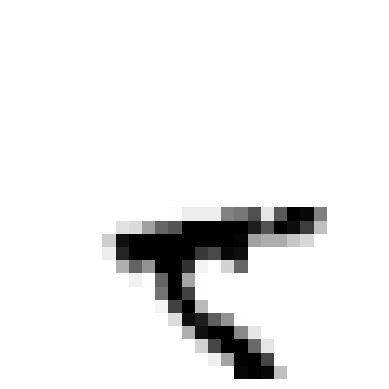

Arriba 10 píxeles


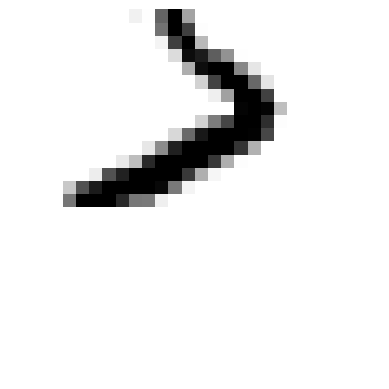

In [36]:
def shift_image(image, dx, dy):
    shifted = np.zeros_like(image)

    h, w = image.shape

    x_src_start = max(0, -dx)
    x_src_end = min(w, w - dx)
    y_src_start = max(0, -dy)
    y_src_end = min(h, h - dy)

    if x_src_start < x_src_end and y_src_start < y_src_end:
        shifted[
            y_src_start + dy:y_src_end + dy,
            x_src_start + dx:x_src_end + dx
        ] = image[
            y_src_start:y_src_end,
            x_src_start:x_src_end
        ]

    return shifted
    
print("No hay desplazamiento")
plot_image(shift_image(X_train[0], 0, 0))     
print("Derecha 10 píxeles")
plot_image(shift_image(X_train[0], 10, 0))
print("Izquierda 10 píxeles")
plot_image(shift_image(X_train[0], -10, 0))
print("Abajo 10 píxeles")
plot_image(shift_image(X_train[0], 0, 10))
print("Arriba 10 píxeles")
plot_image(shift_image(X_train[0], 0, -10))

**19.** Create `X_train_shifted_right_10` with every training image shifted 10 pixels to the right, and plot the first 100. Some digits are cut: which ones, and why?

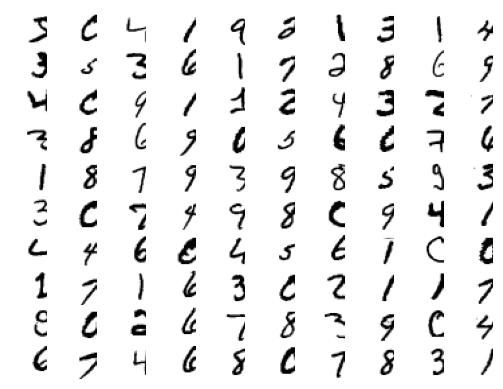

Al desplazar los pixeles hacia la derecha, los dígitos con píxeles cercanos se recortan


In [37]:
X_train_shifted_right_10 = np.array([shift_image(img, 10, 0) for img in X_train])
plot_first_100(X_train_shifted_right_10)

print("Al desplazar los pixeles hacia la derecha, los dígitos con píxeles cercanos se recortan")

**20.** Write `find_limits(image)`, which returns `(top, bottom, left, right)`: the first and last rows and columns that contain ink. Check that the first training image gives `(5, 24, 4, 23)`. Then plot it with its limits drawn as lines (`plt.axhline` and `plt.axvline`).

(np.int64(5), np.int64(24), np.int64(4), np.int64(23))


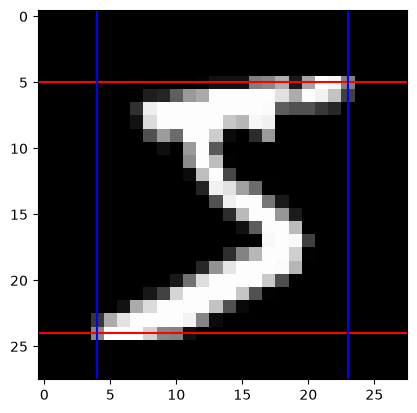

In [38]:
def find_limits(image):
    rows, cols = np.where(image > 0)

    top = rows.min()
    bottom = rows.max()
    left = cols.min()
    right = cols.max()

    return top, bottom, left, right

print(find_limits(X_train[0]))
# (5, 24, 4, 23)

top, bottom, left, right = find_limits(X_train[0])

plt.imshow(X_train[0], cmap="gray")
plt.axhline(top, color="red")
plt.axhline(bottom, color="red")
plt.axvline(left, color="blue")
plt.axvline(right, color="blue")
plt.show()

**21.** Write `crop_image_limits(image)`, which returns the image cropped to its limits. What shape is the first training image once cropped, and why? Remember how MNIST was built.

(20, 20)


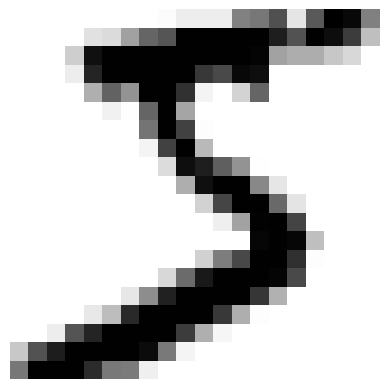

mnist se construyó con imagenes normalizadas de 20x20 píxeles conservando sus proporciones
Posteriormente se añadieron 4 píxeles de relleno para que todas las imágenes fueran de 28x28 píxeles


In [40]:
def crop_image_limits(image):
    top, bottom, left, right = find_limits(image)

    return image[top:bottom+1, left:right+1]

cropped = crop_image_limits(X_train[0])

print(cropped.shape)
plot_image(cropped)

print("mnist se construyó con imagenes normalizadas de 20x20 píxeles conservando sus proporciones")
print("Posteriormente se añadieron 4 píxeles de relleno para que "
"todas las imágenes fueran de 28x28 píxeles")

**22.** Create `X_train_shifted`: every training image shifted by a random amount in each direction, but never so far that ink leaves the frame. Use `find_limits` to know how far each digit can move.

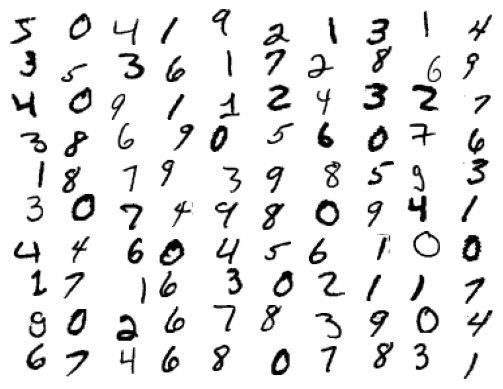

In [41]:
rng = np.random.default_rng(seed=42)

X_train_shifted = np.empty_like(X_train)

for i, image in enumerate(X_train):
    top, bottom, left, right = find_limits(image)

    # Desplazamientos máximos permitidos
    dx = rng.integers(-left, image.shape[1] - right)
    dy = rng.integers(-top, image.shape[0] - bottom)

    X_train_shifted[i] = shift_image(image, int(dx), int(dy))

plot_first_100(X_train_shifted)

**23.** Create `X_train_augmented` by joining, in this order, the original training images, the noisy ones, the binarised ones, the noisy and binarised ones, and the randomly shifted ones. Scale the two binarised sets back to 0 and 255 first, so that all the images share one range. Create `y_train_augmented` with the matching labels. How many images are there?

In [42]:
X_train_augmented = np.concatenate([
    X_train,
    X_train_noisy,
    X_train_binarized * 255,
    X_train_noisy_binarized * 255,
    X_train_shifted
], axis=0)

y_train_augmented = np.tile(y_train, 5)

print(X_train_augmented.shape)
print(y_train_augmented.shape)

print("Esta técnica permite entrenar un modelo con distintas versiones de los"
      "mismos dígitos")

(300000, 28, 28)
(300000,)
Esta técnica permite entrenar un modelo con distintas versiones de losmismos dígitos


### Going further

**24.** *(Optional, no test.)* Building `X_train_shifted` calls a Python function 60,000 times. Write a version without a loop over the images, and measure the speed-up. Is it worth it? Hint: pad the whole array with zeros once, then take for each image the 28×28 window that matches its offset, with fancy indexing.

In [43]:
import numpy as np
import time

def shift_images_vectorized(images, seed=42):
    rng = np.random.default_rng(seed)
    n, h, w = images.shape

    # Límites de cada dígito, sin bucles
    ink = images > 0
    rows = ink.any(axis=2)
    cols = ink.any(axis=1)

    top = rows.argmax(axis=1)
    bottom = h - 1 - rows[:, ::-1].argmax(axis=1)
    left = cols.argmax(axis=1)
    right = w - 1 - cols[:, ::-1].argmax(axis=1)

    # Desplazamientos aleatorios permitidos
    dx = rng.integers(-left, w - right)
    dy = rng.integers(-top, h - bottom)

    # Añadir márgenes de ceros
    padded = np.pad(images, ((0, 0), (h, h), (w, w)))

    # Coordenadas de las ventanas desplazadas
    i = np.arange(n)[:, None, None]
    y = (h - dy)[:, None, None] + np.arange(h)[None, :, None]
    x = (w - dx)[:, None, None] + np.arange(w)[None, None, :]

    return padded[i, y, x]

print("comparación de tiempos entre la versión con bucle y la vectorizada") 
inicio = time.perf_counter()

X_train_shifted_vectorized = shift_images_vectorized(X_train)

tiempo_vectorizado = time.perf_counter() - inicio

print(f"Tiempo vectorizado: {tiempo_vectorizado:.3f} s")


inicio = time.perf_counter()

X_train_shifted = np.empty_like(X_train)

print("Tiempo original")

for i, image in enumerate(X_train):
    top, bottom, left, right = find_limits(image)
    dx = rng.integers(-left, image.shape[1] - right)
    dy = rng.integers(-top, image.shape[0] - bottom)
    X_train_shifted[i] = shift_image(image, int(dx), int(dy))

tiempo_original = time.perf_counter() - inicio
print(f"Aceleración: {tiempo_original / tiempo_vectorizado:.2f}x")

comparación de tiempos entre la versión con bucle y la vectorizada
Tiempo vectorizado: 0.465 s
Tiempo original
Aceleración: 2.02x
